In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

In [2]:
# Initial concentration (mol/L)
CA0 = 0.05

# Common initial reaction rate (mol/L/min)
initial_rate = 0.005

rate_laws = {
    "First_Order": {
        "k": initial_rate / CA0
    },

    "Second_Order": {
        "k": initial_rate / CA0**2
    },

    "Fractional_Order": {
        "k": initial_rate / CA0**1.5
    },

    "Saturation": {
        "Vmax": 0.007,
        "K": 0.02
    },

    "Fourth_Order": {
        "k": initial_rate / CA0**4
    },

    "Zero_Order": {
        "k": initial_rate
    }
}

rate_laws

{'First_Order': {'k': 0.09999999999999999},
 'Second_Order': {'k': 1.9999999999999996},
 'Fractional_Order': {'k': 0.44721359549995787},
 'Saturation': {'Vmax': 0.007, 'K': 0.02},
 'Fourth_Order': {'k': 799.9999999999999},
 'Zero_Order': {'k': 0.005}}

In [3]:
def calculate_rate(CA, reaction, params):

    if reaction == "First_Order":
        return params["k"] * CA

    elif reaction == "Second_Order":
        return params["k"] * CA**2

    elif reaction == "Fractional_Order":
        return params["k"] * CA**1.5

    elif reaction == "Saturation":
        return params["Vmax"] * CA / (params["K"] + CA)

    elif reaction == "Fourth_Order":
        return params["k"] * CA**4

    elif reaction == "Zero_Order":
        return params["k"]

    else:
        raise ValueError("Unknown reaction type")

In [4]:
for reaction, params in rate_laws.items():

    rate = calculate_rate(CA0, reaction, params)

    print(f"{reaction}: {rate:.6f} mol/L/min")

First_Order: 0.005000 mol/L/min
Second_Order: 0.005000 mol/L/min
Fractional_Order: 0.005000 mol/L/min
Saturation: 0.005000 mol/L/min
Fourth_Order: 0.005000 mol/L/min
Zero_Order: 0.005000 mol/L/min


In [5]:
def ode_model(t, y, reaction, params):
    CA = max(y[0], 0.0)

    rate = calculate_rate(CA, reaction, params)

    return [-rate]

In [6]:
# Simulation settings
t_start = 0
t_end = 30
n_points = 121

t_eval = np.linspace(t_start, t_end, n_points)

# Store simulation results
clean_data = {}

for reaction, params in rate_laws.items():

    solution = solve_ivp(
        ode_model,
        (t_start, t_end),
        [CA0],
        t_eval=t_eval,
        args=(reaction, params),
        rtol=1e-9,
        atol=1e-11
    )

    if not solution.success:
        raise RuntimeError(f"{reaction}: {solution.message}")

    clean_data[reaction] = solution.y[0]

In [7]:
for reaction in clean_data:
    clean_data[reaction] = np.maximum(clean_data[reaction], 0)

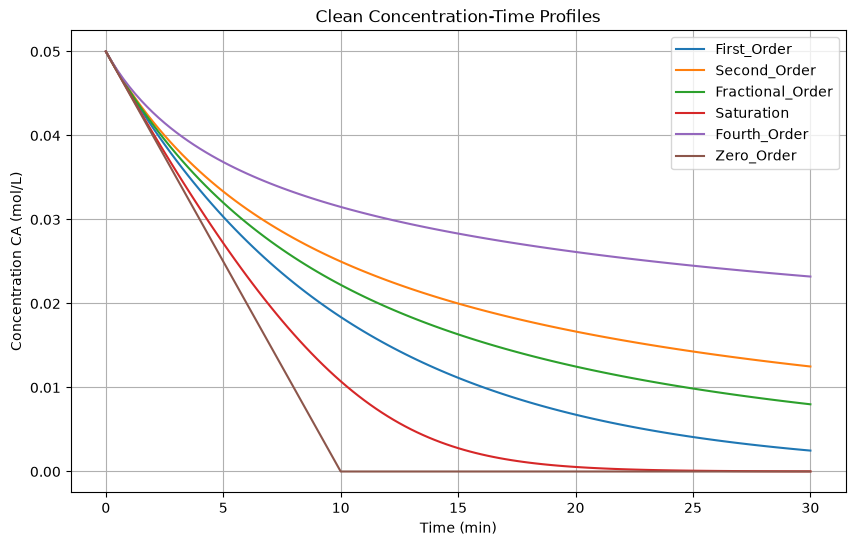

In [8]:
plt.figure(figsize=(10, 6))

for reaction, CA_values in clean_data.items():
    plt.plot(t_eval, CA_values, label=reaction)

plt.xlabel("Time (min)")
plt.ylabel("Concentration CA (mol/L)")
plt.title("Clean Concentration-Time Profiles")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
noise_levels = [0.01, 0.03, 0.05]

n_replicates = 5

np.random.seed(657)

In [11]:
noisy_data = {}

for reaction, CA_values in clean_data.items():

    noisy_data[reaction] = {}

    for noise in noise_levels:

        noisy_data[reaction][noise] = []

        sigma = noise * CA0

        for rep in range(n_replicates):

            noise_values = np.random.normal(
                loc=0,
                scale=sigma,
                size=len(CA_values)
            )

            CA_noisy = CA_values + noise_values

            noisy_data[reaction][noise].append(CA_noisy)

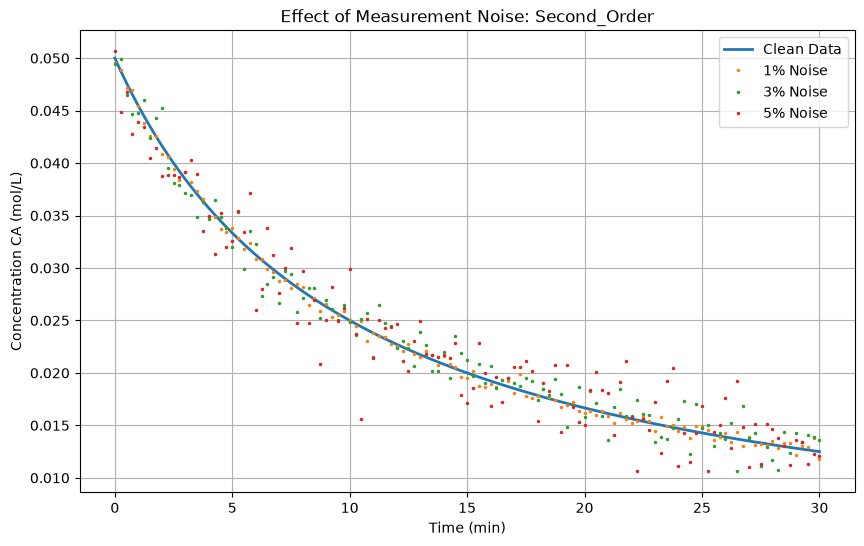

In [12]:
reaction = "Second_Order"

plt.figure(figsize=(10, 6))

plt.plot(
    t_eval,
    clean_data[reaction],
    label="Clean Data",
    linewidth=2
)

for noise in noise_levels:

    plt.plot(
        t_eval,
        noisy_data[reaction][noise][0],
        ".",
        markersize=3,
        label=f"{noise*100:.0f}% Noise"
    )

plt.xlabel("Time (min)")
plt.ylabel("Concentration CA (mol/L)")
plt.title(f"Effect of Measurement Noise: {reaction}")

plt.legend()
plt.grid(True)
plt.show()

In [13]:
dataset = []

for reaction, CA_values in clean_data.items():

    # Add clean observations
    for i, t in enumerate(t_eval):

        dataset.append({
            "reaction": reaction,
            "time_min": t,
            "noise_level": 0,
            "replicate": 0,
            "CA_true": CA_values[i],
            "CA_observed": CA_values[i]
        })

    # Add noisy observations
    for noise in noise_levels:

        for rep in range(n_replicates):

            CA_noisy = noisy_data[reaction][noise][rep]

            for i, t in enumerate(t_eval):

                dataset.append({
                    "reaction": reaction,
                    "time_min": t,
                    "noise_level": noise,
                    "replicate": rep + 1,
                    "CA_true": CA_values[i],
                    "CA_observed": CA_noisy[i]
                })

df = pd.DataFrame(dataset)

df.head()

,reaction,time_min,noise_level,replicate,CA_true,CA_observed
0,First_Order,0.00,0.0,0,0.050000,0.050000
1,First_Order,0.25,0.0,0,0.048765,0.048765
2,First_Order,0.50,0.0,0,0.047561,0.047561
3,First_Order,0.75,0.0,0,0.046387,0.046387
4,First_Order,1.00,0.0,0,0.045242,0.045242


In [14]:
print("Dataset shape:", df.shape)

print("\nReaction types:")
print(df["reaction"].unique())

print("\nNoise levels:")
print(df["noise_level"].unique())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (11616, 6)

Reaction types:
<ArrowStringArray>
[     'First_Order',     'Second_Order', 'Fractional_Order',
       'Saturation',     'Fourth_Order',       'Zero_Order']
Length: 6, dtype: str

Noise levels:
[0.   0.01 0.03 0.05]

Missing values:
reaction       0
time_min       0
noise_level    0
replicate      0
CA_true        0
CA_observed    0
dtype: int64


In [15]:
import os

os.makedirs("reaction_data", exist_ok=True)
df.to_csv("reaction_data/reaction_dataset.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!
